> **Language & Quick Links**: [🇰🇷 한국어 (`notebooks/ko/stage0_overview_walkthrough_ko.ipynb`)](../ko/stage0_overview_walkthrough_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Methodology Guide](../../methodology/METHODOLOGY_EN.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open Live Studio Tab](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=overview)
>
> **Lifecycle Navigation**: **[▶ 0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb)** → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → [Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) → [Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) → [Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)

---

# 0. End-to-End Entrypoint — 8-Phase Engineering Pipeline & 5-Stage Agentic Ontology Walkthrough
## Prepare → Analyze → Parse → Integrate → Build Graph → Build Agent → Answer (GQL) → Verify & Gate

This master entrypoint notebook walks through the complete **Agentic Ontology Starter Pack v2.0** methodology end to end. Rather than isolated data exploration, it connects **1. Preparation → 2. Analysis & CQ Design → 3. Markdown Parsing & SHA-256 Anchoring → 4. 3-Layer Wiki & Semantic Rule Integration → 5. Physical Property Graph Construction → 6. 8-Tool MCP & 2-Pass Agent Setup → 7. Parameterized ISO GQL & Grounded Answering → 8. 4-Tier Lineage & 50-Trial Benchmark Verification**, showing intermediate tables, bound GQL variables, data outputs, and graph design schematics at every phase.

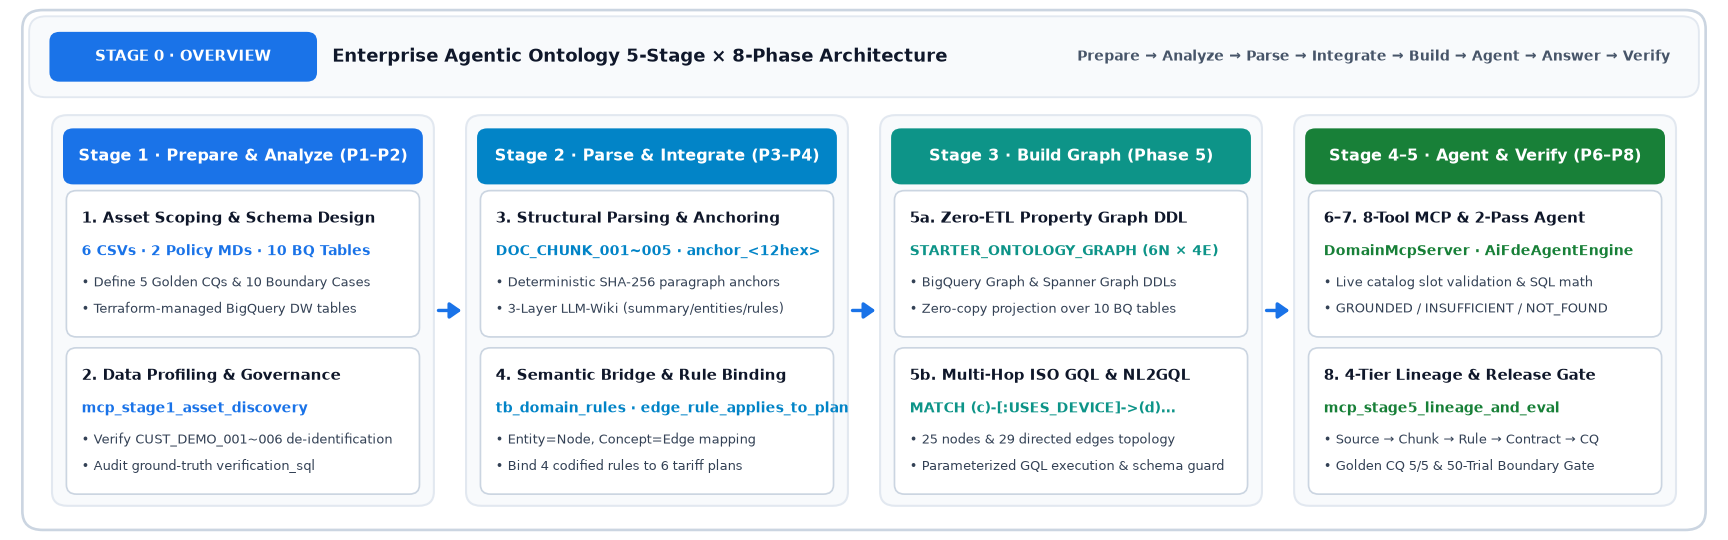

### 8-Phase Engineering Flow & Bilingual Notebook Navigation Map (`notebooks/ko/` · `notebooks/en/`)

| Engineering Phase | Canonical Stage | Core Modules & MCP Tools | Intermediate Data, Tables & Graph Schematics | Korean Notebook (`ko/`) | English Notebook (`en/`) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1. Prepare**<br>**2. Analyze** | **Stage 1**<br>(`Step 1.1`–`1.2`) | `terraform/bigquery.tf`<br>`mcp_stage1_asset_discovery`<br>`H.check_cq_sql()` | Raw CSV/MD inventory, 10-table ER blueprint, de-identified contracts, subsidy heatmap, 5 Golden CQs SQL check | [`stage1_ko`](../ko/stage1_asset_and_cq_ko.ipynb) | [`stage1_en`](./stage1_asset_and_cq_en.ipynb) |
| **3. Parse**<br>**4. Integrate** | **Stage 2**<br>(`Step 2.1`–`2.2`) | `pipeline/ingest.py`<br>`mcp_stage2_wiki_and_semantic`<br>`H.propose_triples()` | `DOC_CHUNK` regex parsing & SHA-256 anchor table, 3-Layer Wiki, Gemini triple extraction, Semantic Graph schematic | [`stage2_ko`](../ko/stage2_wiki_and_semantic_graph_ko.ipynb) | [`stage2_en`](./stage2_wiki_and_semantic_graph_en.ipynb) |
| **5. Build Graph** | **Stage 3**<br>(`Step 3.1`–`3.2`) | `pipeline/graph_builder.py`<br>`mcp_stage3_property_graph`<br>`H.run_gql()` / `H.nl2gql()` | 6 Node × 4 Edge metamodel schematic, BQ/Spanner DDL, full topology & 1..2-hop ego graph, parameterized ISO GQL | [`stage3_ko`](../ko/stage3_property_graph_bigquery_spanner_ko.ipynb) | [`stage3_en`](./stage3_property_graph_bigquery_spanner_en.ipynb) |
| **6. Build Agent**<br>**7. Answer** | **Stage 4**<br>(`Step 4.1`–`4.2`) | `src/agent/mcp_server.py`<br>`src/agent/reasoning_engine.py`<br>`mcp_stage4_agent_orchestration` | 2-Pass agent orchestration schematic, 8-tool MCP catalog, slot parsing, 180d penalty curve, Golden CQ & boundary answers | [`stage4_ko`](../ko/stage4_agent_and_mcp_execution_ko.ipynb) | [`stage4_en`](./stage4_agent_and_mcp_execution_en.ipynb) |
| **8. Verify & Gate** | **Stage 5**<br>(`Step 5.1`–`5.2`) | `pipeline/validator.py`<br>`mcp_stage5_lineage_and_eval`<br>`H.recheck_cq()` | 4-Tier lineage table & multipartite graph, live CQ re-audit, Boundary 50-trial metrics & Gate 1..5 checklist | [`stage5_ko`](../ko/stage5_lineage_and_evaluation_ko.ipynb) | [`stage5_en`](./stage5_lineage_and_evaluation_en.ipynb) |

### 3-Track Selective Adoption Model (`config/starter_config.json`)

| Track | Active Stages | Graph Engine | Target Scenario |
| :--- | :--- | :--- | :--- |
| **Track 1 · Lite** | `Stage 1 → Stage 2 → Stage 4` | `none` | Fast-track deployment using 3-Layer LLM-Wiki and codified rule tables without a physical property graph |
| **Track 2 · Standard** | `Stage 1 → Stage 2 → Stage 3 → Stage 4` | `bigquery` / `spanner` | Unifying 4 structured DW ledgers and unstructured rules into a Zero-ETL Property Graph for multi-hop ISO GQL |
| **Track 3 · Full-Stack** | `Stage 1 → Stage 2 → Stage 3 → Stage 4 → Stage 5` | `bigquery` | Full lifecycle operation including 4-Tier lineage, 5 Golden CQs, 50-trial boundary benchmark, and Cloud Run release gates |


In [1]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("en")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Architecture Blueprint] 8-Phase Engineering Pipeline & 10-Table Schema Blueprint


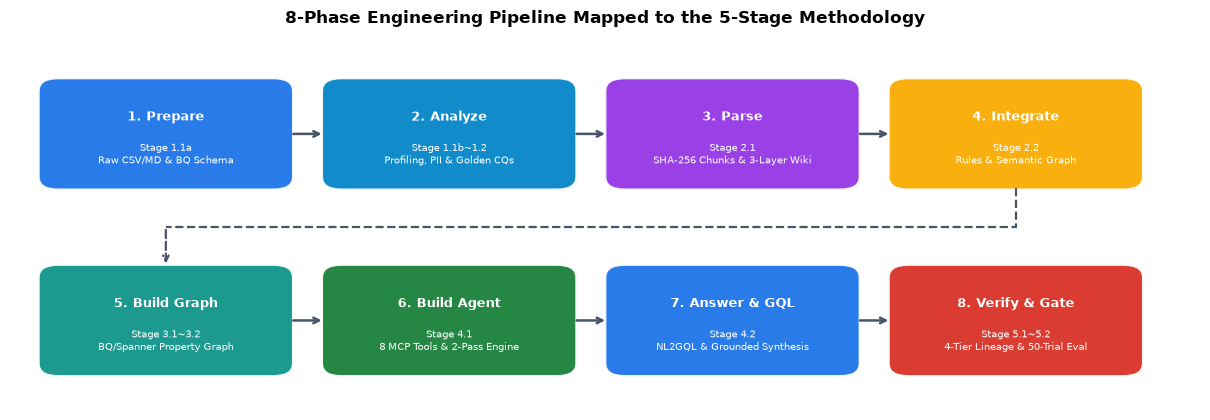

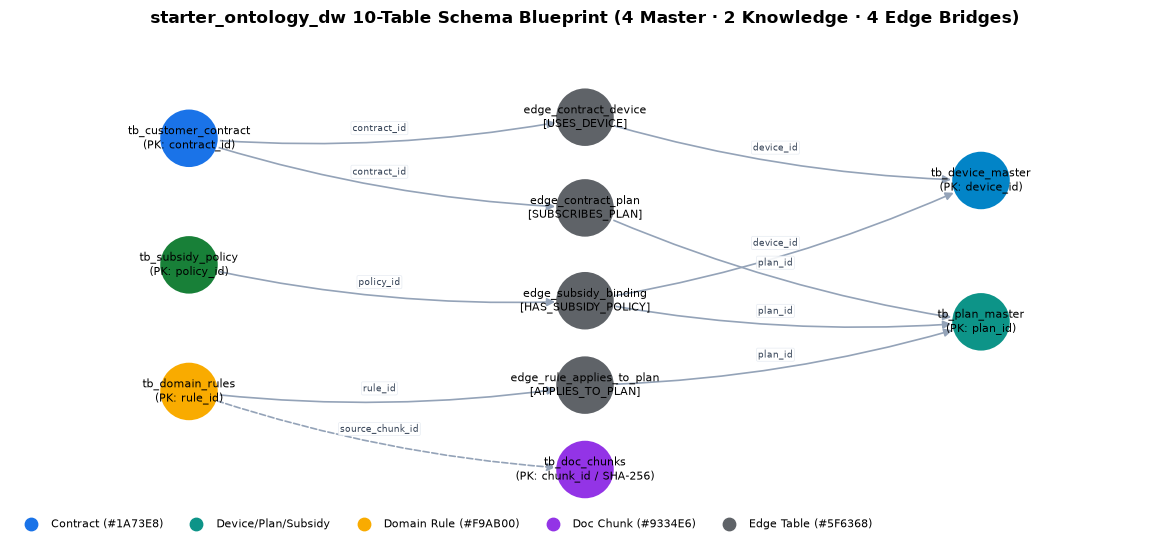

In [2]:
H.draw_eight_phase_flow()
H.draw_table_er_blueprint()


### 2. [Phase 1–2 · Stage 1: Prepare & Analyze] Raw Input Inventory & BigQuery 10-Table Profiling (`mcp_stage1_asset_discovery` + `%%bqsql`)


In [3]:
H.show(H.raw_inputs_inventory())
res_s1 = server.execute_tool("mcp_stage1_asset_discovery")
H.show_tool(res_s1)


,input_file,asset_type,volume,key_contents
0,01_guides/sample_policy_guide.md,Unstructured Policy Guide,"16 lines (1,363 chars)","DOC_CHUNK_001~003 (Subsidy Cap, 180d Retention, Prorated Formula)"
1,01_guides/sample_welfare_exemption_guide.md,Unstructured Policy Guide,"11 lines (1,252 chars)","DOC_CHUNK_004~005 (Senior/Welfare Exemption, 24M TCO Rule)"
2,03_tables/devices.csv,Master CSV (Structured),4 rows,"device_id, pet_name, storage, manufacturer, factory_price, release_date"
3,03_tables/plans.csv,Master CSV (Structured),6 rows,"plan_id, plan_name, tier_category, monthly_fee, min_maintenance_days, selective_discou..."
4,03_tables/subsidies.csv,Master CSV (Structured),5 rows,"policy_id, device_id, plan_id, basic_subsidy, distribution_subsidy, mandatory_retentio..."
5,03_tables/customer_contracts.csv,Master CSV (Structured),6 rows,"contract_id, customer_id (CUST_DEMO_*), device_id, plan_id, contract_type, elapsed_day..."
6,03_tables/domain_rules.csv,Semantic Rule CSV,4 rows,"rule_id, rule_name, rule_category, condition_expr, formula_expr, source_chunk_id"
7,03_tables/rule_plan_edges.csv,Semantic Bridge CSV,12 rows,"edge_id, rule_id, plan_id, source_chunk_id, relation_label_ko"
8,04_cq/golden_competency_questions.json,Golden CQ Benchmark Spec,5 items,"5 Golden CQs with expected_math, verification_sql, grounded_chunk"
9,04_cq/boundary_cases.json,Boundary Benchmark Spec,10 items,"10 Boundary Cases with root_cause_code, accept_answer_status"


**`mcp_stage1_asset_discovery`** · status `SUCCESS` · steps `profile_tables, scan_guides, prune_noise, tag_pii_governance` · BigQuery jobs 2 (910 ms)

BigQuery `seanjung-poc.starter_ontology_dw` 테이블 10개, 총 59행 실측 · 비식별 규칙 위반 고객 ID 0건

- `job_WOGW86SKHUueeeCtVScAgwFRjMrx`
- `job_WCxJHYe80F76VglYS3d_i-4GdDvG`

In [4]:
%%bqsql df_tables
SELECT table_id, row_count, size_bytes,
  CASE WHEN STARTS_WITH(table_id, 'edge_') THEN '3_edge_bridge'
       WHEN table_id IN ('tb_doc_chunks', 'tb_domain_rules') THEN '2_knowledge_wiki'
       ELSE '1_structured_master' END AS table_role
FROM `seanjung-poc.starter_ontology_dw.__TABLES__`
ORDER BY table_role, table_id


,table_id,row_count,size_bytes,table_role
0,tb_customer_contract,6,856,1_structured_master
1,tb_device_master,4,292,1_structured_master
2,tb_plan_master,6,423,1_structured_master
3,tb_subsidy_policy,5,382,1_structured_master
4,tb_doc_chunks,5,2784,2_knowledge_wiki
5,tb_domain_rules,4,1858,2_knowledge_wiki
6,edge_contract_device,6,368,3_edge_bridge
7,edge_contract_plan,6,379,3_edge_bridge
8,edge_rule_applies_to_plan,12,1450,3_edge_bridge
9,edge_subsidy_binding,5,342,3_edge_bridge


,table_id,row_count,size_bytes,table_role
0,tb_customer_contract,6,856,1_structured_master
1,tb_device_master,4,292,1_structured_master
2,tb_plan_master,6,423,1_structured_master
3,tb_subsidy_policy,5,382,1_structured_master
4,tb_doc_chunks,5,2784,2_knowledge_wiki
5,tb_domain_rules,4,1858,2_knowledge_wiki
6,edge_contract_device,6,368,3_edge_bridge
7,edge_contract_plan,6,379,3_edge_bridge
8,edge_rule_applies_to_plan,12,1450,3_edge_bridge
9,edge_subsidy_binding,5,342,3_edge_bridge


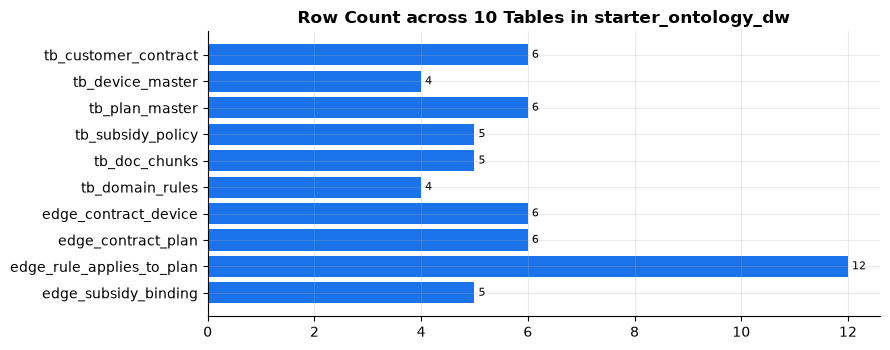

In [5]:
H.show(df_tables)
H.bar(df_tables, "table_id", "row_count", H.t("starter_ontology_dw 10개 테이블 역할별 적재 행 수 (실측)", "Row Count across 10 Tables in starter_ontology_dw"), horizontal=True)


### 3. [Phase 3–4 · Stage 2: Parse & Integrate] SHA-256 Guide Chunking, 3-Layer Wiki Compilation & Semantic Ontology Schematic


,chunk_id,source_file,section_title,chars,computed_anchor,bq_stored_anchor,sha256_match,excerpt
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,222,anchor_a52e1a72869f,anchor_a52e1a72869f,True,## 1. General Principles
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),467,anchor_3003b683cea0,anchor_3003b683cea0,True,## 2. 180-Day Baseline Plan Commitment Rule
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,444,anchor_47971ec8e4d8,anchor_47971ec8e4d8,True,## 3. Penalty Settlement Computation Formula
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,583,anchor_269d9c42e05c,anchor_269d9c42e05c,True,## 4. Statutory Penalty Exemption Clauses (위약금 면제 특례 규정)
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,472,anchor_4fbaf9c5cba8,anchor_4fbaf9c5cba8,True,## 5. Public Subsidy vs. 25% Selective Contract Comparison (`RULE_TCO_COMPA


,wiki_layer,file,lines,gcs_object_uri,role
0,Layer 1 (Executive Summary),summary.md,8,gs://seanjung-poc-starter-ontology/ontology/summary.md,"Domain scope, OKF v0.2 framework, total chunks & BigQuery tables"
1,Layer 2 (Core Entities),entities.md,31,gs://seanjung-poc-starter-ontology/ontology/entities.md,"Compiled directory of contracts, devices, plans, and subsidy policies"
2,Layer 3 (Semantic Concepts),concepts.md,7,gs://seanjung-poc-starter-ontology/ontology/concepts.md,"Entity=Node, Concept=Edge relationship definitions (4 edge types)"
3,Layer 3 (Codified Rules),rules.md,22,gs://seanjung-poc-starter-ontology/ontology/rules.md,"Deterministic business rules with condition_expr, formula_expr & chunk anchors"


**`mcp_stage2_wiki_and_semantic`** · status `SUCCESS` · steps `compile_3layer_wiki, extract_hash_anchors, bind_semantic_bridges` · BigQuery jobs 1 (515 ms)

GCS 객체 8개 · 청크/규칙 조인 5행

- `job_cc2YqkgUXDYht8V9i9TQSETtLXOz`

,chunk_id,source_file,section_title,anchor,trust_tier,rule_id,rule_name,formula_expr
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,anchor_a52e1a72869f,GOLDEN_VERIFIED,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0,GOLDEN_VERIFIED,NaN,NaN,NaN
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,anchor_47971ec8e4d8,GOLDEN_VERIFIED,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,anchor_269d9c42e05c,GOLDEN_VERIFIED,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE)
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8,GOLDEN_VERIFIED,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...


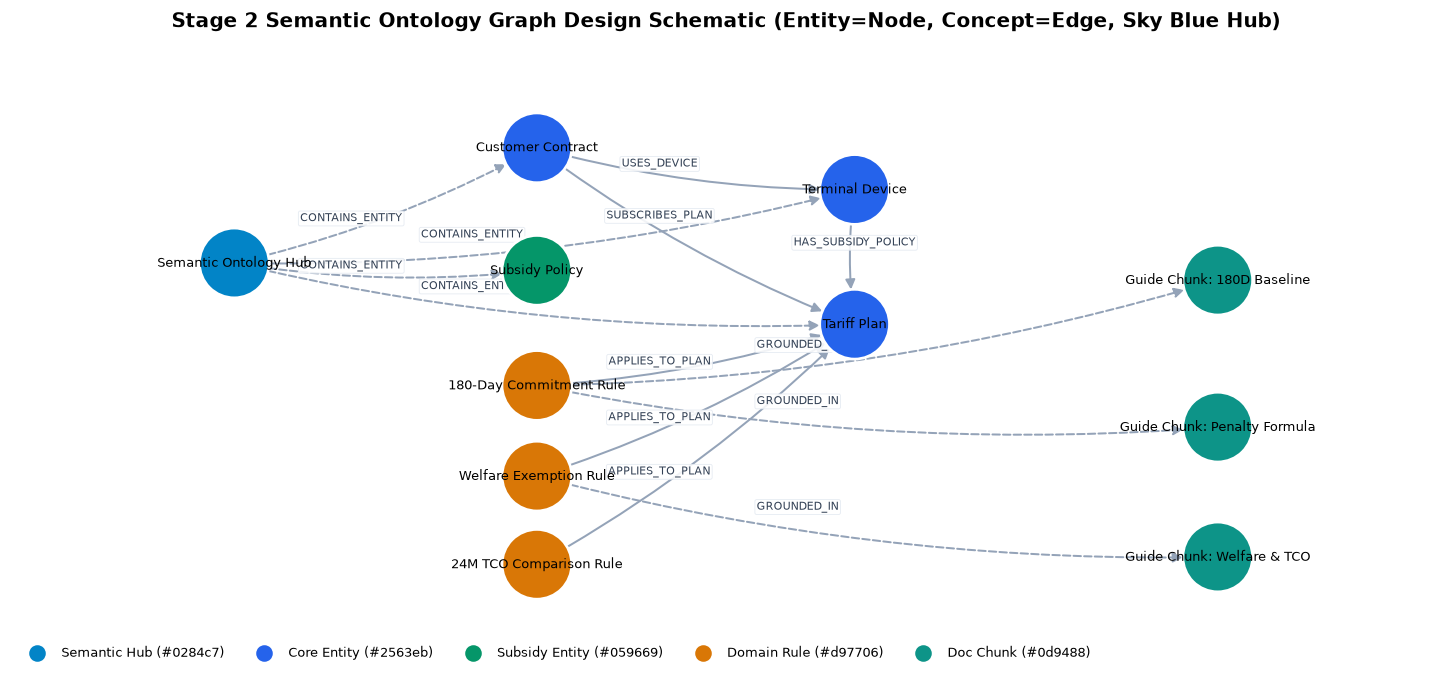

In [6]:
H.show(H.parse_guides_live_demo())
df_wiki, manifest = H.wiki_compilation_summary()
H.show(df_wiki)
res_s2 = server.execute_tool("mcp_stage2_wiki_and_semantic")
H.show_tool(res_s2, "anchored_chunks")
H.draw_semantic_design_graph()


### 4. [Phase 5 · Stage 3: Build Property Graph] `STARTER_ONTOLOGY_GRAPH` Metamodel, Executed GQL & Bound Variables, and Full Topology (`%%bqsql` + `H.run_gql`)


**`mcp_stage3_property_graph`** · status `SUCCESS` · steps `promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates` · BigQuery jobs 2 (892 ms)

노드 테이블 중복 키 0건 · GQL 경로(Device→Plan←Rule) 10개

- `job_vUdQEuoOZUJBlfiaRGIcKaWH74Uz`
- `job_ViqeGogG-DJ0mQKe3_Ymp0RSVpM1`

,node_table,row_count,duplicate_keys
0,tb_device_master,4,0
1,tb_plan_master,6,0
2,tb_subsidy_policy,5,0
3,tb_customer_contract,6,0
4,tb_doc_chunks,5,0
5,tb_domain_rules,4,0


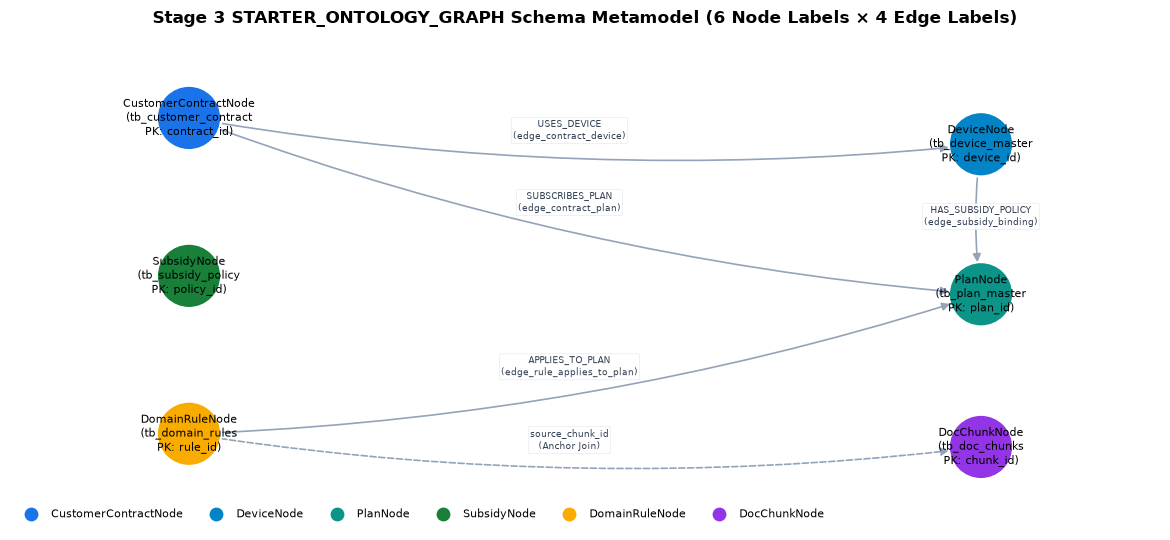

In [7]:
res_s3 = server.execute_tool("mcp_stage3_property_graph")
H.show_tool(res_s3, "node_tables")
H.draw_property_graph_metamodel()


In [8]:
%%bqsql df_paths
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (a)-[e]->(b)
RETURN TO_JSON(p) AS path


,path
0,"""[{\""identifier\"":\""rh8AAAANAAAApgEAAAAAAAAArA..."
1,"""[{\""identifier\"":\""rh4AAAANAAAApgEAAAAAAAAArA..."
2,"""[{\""identifier\"":\""rh4AAAANAAAApgEAAAAAAAAArA..."
3,"""[{\""identifier\"":\""rh4AAAANAAAApgEAAAAAAAAArA..."
4,"""[{\""identifier\"":\""rh4AAAANAAAApgEAAAAAAAAArA..."
5,"""[{\""identifier\"":\""rh4AAAANAAAApgUAAAAAAAAArA..."
6,"""[{\""identifier\"":\""rh4AAAANAAAApgUAAAAAAAAArA..."
7,"""[{\""identifier\"":\""rh4AAAANAAAApgUAAAAAAAAArA..."
8,"""[{\""identifier\"":\""rh4AAAANAAAApgUAAAAAAAAArA..."
9,"""[{\""identifier\"":\""riUAAAANAAAApgUAAAAAAAAArB..."


#### 3-Hop ISO GQL Execution (Customer Contract → Device/Plan ← Domain Rule + DocChunk)
- **BigQuery ISO GQL Execution**: status `SUCCESS` · job `job_Shjoqj3296UIzgzdu2a3DFxeWtJx` · `450 ms` · `2 rows`

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | Target BigQuery Property Graph |
| `c.customer_id` | `'CUST_DEMO_001'` | CustomerContractNode filter parameter |
| `ch.chunk_id` | `ap.source_chunk_id` | DocChunkNode SHA-256 anchor join key |

**2) Executed ISO GQL Statement**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
      (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode),
      (ch:DocChunkNode)
WHERE c.customer_id = 'CUST_DEMO_001' AND ch.chunk_id = ap.source_chunk_id
RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name,
       r.rule_id AS rule_id, ap.source_chunk_id AS chunk_id, ch.content_sha256 AS sha256_anchor
ORDER BY r.rule_id
```

,customer_id,device_name,plan_name,rule_id,chunk_id,sha256_anchor
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0
1,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8


**Extracted physical graph nodes: `19` · edges: `29`**

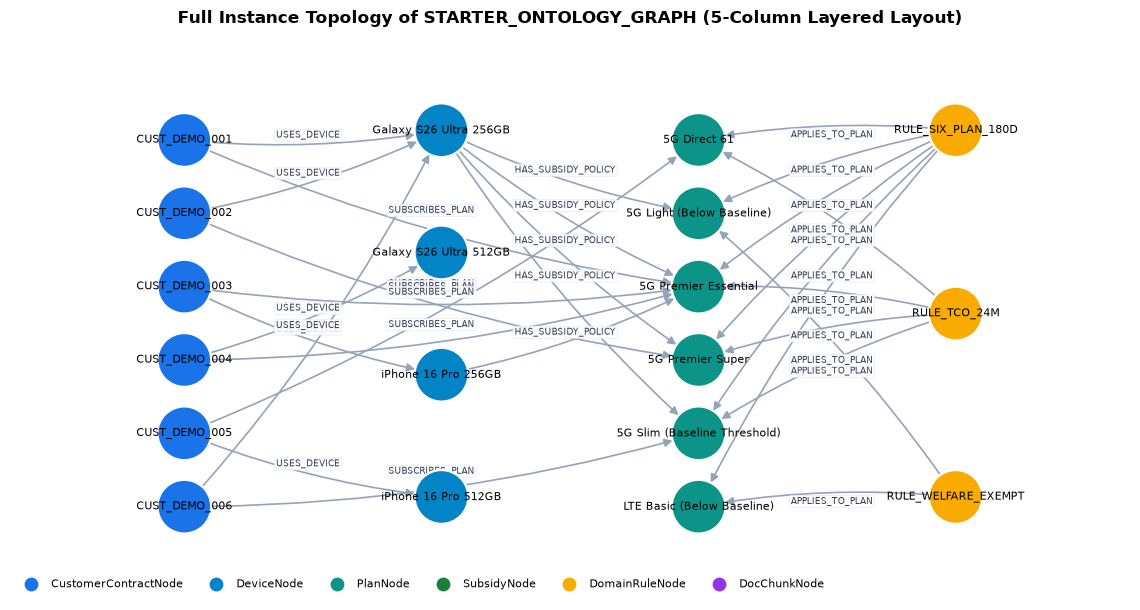

In [9]:
gql_cust_rules = """GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
      (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode),
      (ch:DocChunkNode)
WHERE c.customer_id = 'CUST_DEMO_001' AND ch.chunk_id = ap.source_chunk_id
RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name,
       r.rule_id AS rule_id, ap.source_chunk_id AS chunk_id, ch.content_sha256 AS sha256_anchor
ORDER BY r.rule_id"""
_ = H.run_gql(
    gql_cust_rules,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", H.t("BigQuery 프로퍼티 그래프 식별자", "Target BigQuery Property Graph")),
        "c.customer_id": ("'CUST_DEMO_001'", H.t("CustomerContractNode 고객 필터 변수", "CustomerContractNode filter parameter")),
        "ch.chunk_id": ("ap.source_chunk_id", H.t("DocChunkNode SHA-256 앵커 조인 키", "DocChunkNode SHA-256 anchor join key")),
    },
    title=H.t("3-Hop ISO GQL 실행 예시 (고객 약정 → 단말/요금제 ← 도메인 규칙 + 근거 청크)",
              "3-Hop ISO GQL Execution (Customer Contract → Device/Plan ← Domain Rule + DocChunk)"),
)
nodes, edges = H.paths_to_graph(H.pdf(df_paths)["path"])
H.md(H.t(f"**실측 추출된 물리 그래프 노드 `{len(nodes)}`개 · 엣지 `{len(edges)}`개**", f"**Extracted physical graph nodes: `{len(nodes)}` · edges: `{len(edges)}`**"))
H.draw_graph(nodes, edges, H.t("STARTER_ONTOLOGY_GRAPH 전체 인스턴스 토폴로지 (5계층 레이어 배치)", "Full Instance Topology of STARTER_ONTOLOGY_GRAPH (5-Column Layered Layout)"), legend=H.LABEL_COLORS)


### 5. [Phase 6–7 · Stage 4: Build Agent & Answer] 2-Pass Agent Blueprint, Live NL-to-GQL & Golden CQ Execution


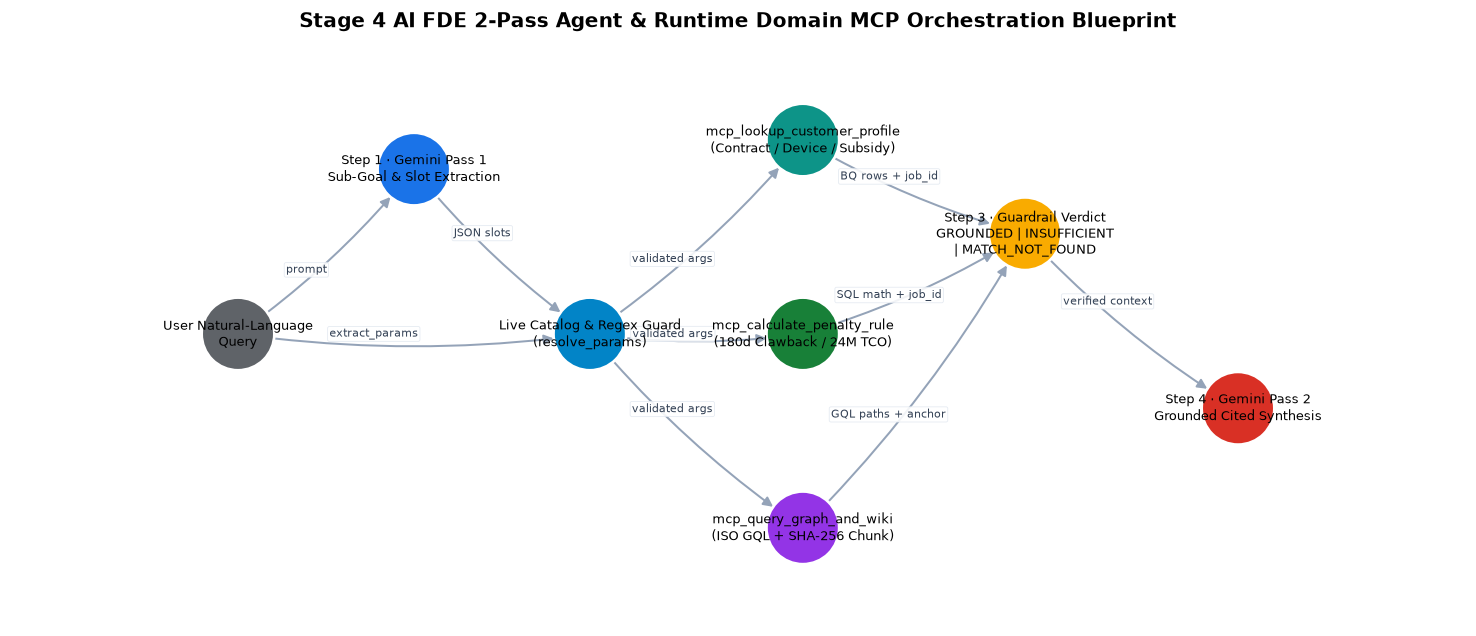

**Q.** Show each customer's device name, subscribed plan name, and monthly fee ordered by customer ID
- Gemini `gemini-3.8-flash`: Retrieves the device name and subscribed plan details for each customer contract, ordered by customer ID. (tokens 1,578, 5,237 ms)

Attempt 1 · status `SUCCESS` · job `job_a5_rty9vltAPerSy6cO_nqSe2Oxx` · 415 ms · 6 rows

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `GRAPH` | `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` | Target BigQuery Property Graph |

**2) Executed ISO GQL Statement**
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode) RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw ORDER BY customer_id LIMIT 50
```

,customer_id,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


#### Golden CQ-03 · 120-Day Prorated Penalty Calculation
**Q.** CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 시 위약금과 근거 앵커는?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Light(37,000원)"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 413 | `job_Dt2ONRAjpHFAStU-pT5XYJDLfhpl` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 793 | `job_YQK3dS5LZJeCwUK9XrwRKF9u7tRu`, `job_sB78HU_yzMez--RxcsI1nl27v9nS` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 442 | `job_2rAATlyn5mc9tbQ6CPmlvz-_SN2_` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Light(37,000원)"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,912 tokens, LLM 16,432 ms / total 18.51 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### **결론**
> CUST_DEMO_001 고객이 개통 120일 시점에 월 37,000원 요금제(5G Light)로 하향 변경할 경우 발생하는 위약금은 **100,000원**입니다.
>
> - **위약금 산식**: `(기본 공시지원금 - 변경 요금제 공시지원금) × (180 - 유지일수) / 180`
> - **산정 내역**: `(450,000원 - 150,000원) × (180일 - 120일) / 180 = 300,000원 × (60 / 180) = 100,000원`
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> - **고객 ID**: `CUST_DEMO_001` (계약 ID: `CONTRACT_DEMO_101`)
> - **약정 유형**: 공시지원금 (`PUBLIC_SUBSIDY`, 약정기간 24개월)
> - **복지 상태**: `NONE`
> - **기기명**: Galaxy S26 Ultra 256GB (출고가: 1,698,400원)
> - **현재 요금제**: 5G Premier Essential (월정액: 85,000원)
> - **현재 요금제 기본 공시지원금**: 450,000원 (추가지원금 67,500원, 총 지원금 517,500원)
> - **하향 대상 요금제**: 5G Light (월정액: 37,000원)
> - **하향 대상 요금제 기본 공시지원금**: 150,000원
> - **기준선 요금**: 45,000원 (의무 유지 기간: 180일)
> - **경과 일수**: 120일 (잔여 일수: 60일)
> - **위약금 상태**: 일할 위약금 부과 (`PRORATED_PENALTY`)
> - **산출 위약금**: 100,000원
>
> ---
>
> ### **규칙·원문 근거**
>
> 1. **위약금 계산 규칙**: `RULE_SIX_PLAN_180D` (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)
>    - **조건**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>    - **산식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>    - **근거 청크 ID 및 앵커**:
>      - `DOC_CHUNK_003` (`anchor_47971ec8e4d8`)
>      - `DOC_CHUNK_002` (Baseline Plan Commitment (Six-Plan Rule), `anchor_3003b683cea0`)
>    - **원문 내용 요약**: 공시지원금을 지급받은 가입자가 개통 후 180일 이내에 기준선(5G 45,000원/월) 미만으로 하향할 경우 유지일수를 반영하여 차액정산금을 일할 부과함.
>
> 2. **기타 연계 규칙**:
>    - `RULE_SUBSIDY_CAP` (`DOC_CHUNK_001`, `anchor_a52e1a72869f`): 총 지원금 산정 규칙
>    - `RULE_TCO_24M` (`DOC_CHUNK_005`, `anchor_4fbaf9c5cba8`): 24개월 총소유비용 비교 규칙
>
> ---
>
> ### **실행 정보**
>
> - **Customer Profile 조회 Job ID**: `job_Dt2ONRAjpHFAStU-pT5XYJDLfhpl`
> - **Penalty Rule 계산 Job IDs**: `job_YQK3dS5LZJeCwUK9XrwRKF9u7tRu`, `job_sB78HU_yzMez--RxcsI1nl27v9nS`
> - **Graph & Wiki 조회 Job ID**: `job_2rAATlyn5mc9tbQ6CPmlvz-_SN2_`

#### Golden CQ-05 · Senior Welfare Exemption & Multi-Hop Graph Path
**Q.** CUST_DEMO_003(시니어 복지 대상) 고객이 개통 88일차에 시니어 요금제로 변경 시 위약금 면제 여부와 그래프 경로 확인해줘

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"customer_id": "CUST_DEMO_003", "elapsed_days": 88, "target_plan_mention": "시니어 요금제"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 424 | `job_v9dvSNTk1FV1puZ4thMf3lgZ3kSc` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,119 | `job_HQIS8SnDWT-CsSfmEZK_l-ZVeURo`, `job_Lv8GPgJyMRa7QKu9RE2emGm533Rp` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 728 | `job_1xOyfLq23rPy7KkqWojaeh3aBzQE` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"customer_id": "CUST_DEMO_003", "elapsed_days": 88, "target_plan_mention": "시니어 요금제"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_003'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,955 tokens, LLM 14,144 ms / total 16.42 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### **결론**
> CUST_DEMO_003 고객(만 65세 이상, 시니어 복지 특례 대상자)은 개통 88일차에 시니어 요금제로 변경하더라도 **위약금이 100% 면제되어 부과 위약금은 0원(`penalty_krw: 0`)**입니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> - **고객 및 계약 프로필 (`mcp_lookup_customer_profile`)**
>   - **고객 ID / 계약 ID**: `CUST_DEMO_003` / `CONTRACT_DEMO_103`
>   - **고객 세그먼트 / 연령대**: `Senior_Welfare` / `65+`
>   - **복지 특례 상태 (`welfare_status`)**: `SENIOR_EXEMPT`
>   - **약정 유형 / 유지 일수**: `PUBLIC_SUBSIDY` (공시지원금 약정, 24개월) / `88일`
>   - **기기 정보**: `iPhone 16 Pro 256GB` (출고가: 1,700,000원)
>   - **현재 요금제**: `5G Premier Essential` (월 85,000원)
>   - **수혜 지원금**: 기본 지원금 400,000원 + 추가 지원금 60,000원 = 총 460,000원
>
> - **위약금 계산 결과 (`mcp_calculate_penalty_rule`)**
>   - **위약금 상태 (`penalty_status`)**: `EXEMPT_WELFARE`
>   - **발생 위약금 (`penalty_krw`)**: **0원**
>
> - **온톨로지 그래프 탐색 경로 (`mcp_query_graph_and_wiki`)**
>   - **그래프 엔진 / 대상**: BigQuery (`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`)
>   - **GQL 경로 패턴**: `(c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)`
>   - **탐색 홉 수 / 매칭 노드 수**: 3 hops / 4 nodes
>   - **연결 매칭 경로**:
>     1. `(CONTRACT_DEMO_103)` → `USES_DEVICE` → `(iPhone 16 Pro 256GB)`
>     2. `(CONTRACT_DEMO_103)` → `SUBSCRIBES_PLAN` → `(5G Premier Essential, 85,000원)`
>     3. `(5G Premier Essential)` ← `APPLIES_TO_PLAN (180일 기준선 유지 의무 적용)` ← `(RULE_SIX_PLAN_180D)`
>     4. `(5G Premier Essential)` ← `APPLIES_TO_PLAN (24개월 공시 vs 선택약정 비교 적용)` ← `(RULE_TCO_24M)`
>
> ---
>
> ### **규칙·원문 근거**
>
> 1. **위약금 면제 규칙 (`RULE_WELFARE_EXEMPT`)**
>    - **규칙명**: 시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례
>    - **조건 및 산식**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')` 일 때, `penalty = 0 (SENIOR_EXEMPT)`
>    - **내용**: 만 65세 이상 시니어 복지 특례(`SENIOR_EXEMPT`) 대상자가 시니어/복지 요금제로 전환 시 개통 180일 이내라도 차액정산 위약금을 100% 면제(0원)합니다.
>    - **근거 청크 ID**: `DOC_CHUNK_004` (앵커: `anchor_269d9c42e05c`)
>
> 2. **요금제 유지 의무 규칙 및 TCO 규칙 (참고 그래프 연결 규칙)**
>    - `RULE_SIX_PLAN_180D` (`DOC_CHUNK_002`, 앵커: `anchor_3003b683cea0`)
>    - `RULE_TCO_24M` (`DOC_CHUNK_005`, 앵커: `anchor_4fbaf9c5cba8`)
>
> ---
>
> ### **실행 정보**
>
> - **고객 프로필 조회 Job ID**: `job_v9dvSNTk1FV1puZ4thMf3lgZ3kSc`
> - **위약금 계산 Job ID**: `job_HQIS8SnDWT-CsSfmEZK_l-ZVeURo`, `job_Lv8GPgJyMRa7QKu9RE2emGm533Rp`
> - **그래프 및 온톨로지 탐색 Job ID**: `job_1xOyfLq23rPy7KkqWojaeh3aBzQE`

In [10]:
H.draw_agent_architecture()
node_labels, edge_labels, _ = H.graph_metadata()
schema_str = H.schema_text(node_labels, edge_labels)
_ = H.nl2gql(H.t("각 고객이 사용 중인 단말기명과 가입 요금제명, 월정액을 고객 ID 순으로 보여줘",
                 "Show each customer's device name, subscribed plan name, and monthly fee ordered by customer ID"), schema_str)
H.show_agent(agent.execute_cycle("CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 시 위약금과 근거 앵커는?"),
             H.t("Golden CQ-03 · 120일 일할 차액정산 위약금 산출", "Golden CQ-03 · 120-Day Prorated Penalty Calculation"))
H.show_agent(agent.execute_cycle("CUST_DEMO_003(시니어 복지 대상) 고객이 개통 88일차에 시니어 요금제로 변경 시 위약금 면제 여부와 그래프 경로 확인해줘"),
             H.t("Golden CQ-05 · 시니어 복지 면제 & 멀티홉 그래프 경로", "Golden CQ-05 · Senior Welfare Exemption & Multi-Hop Graph Path"))


### 6. [Phase 8 · Stage 5: Verify & Release Gate] 4-Tier Lineage Summary & Gate 1–5 Readiness Verdict


In [11]:
res_s5 = server.execute_tool("mcp_stage5_lineage_and_eval")
H.show_tool(res_s5)
H.show(H.gate_checklist_table())


**`mcp_stage5_lineage_and_eval`** · status `SUCCESS` · steps `build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures` · BigQuery jobs 1 (437 ms)

리니지 조인 12행 · 최근 검증 리포트: {'evaluated_at': '2026-09-27T19:42:34+09:00', 'total_cqs': 5, 'passed': 5, 'accuracy_rate': 100.0, 'method': 'verification_sql(BigQuery) vs expected_math + live agent answer (Vertex AI gemini-3.8-flash + BigQuery MCP)'}

- `job_LQ1auMXsP_PqWXdXoUE1TkxkKtAF`

,gate,criterion,measured_value,verdict
0,Gate 1 (Stage 1: Prepare & Analyze),"10 BQ tables loaded, 0 PII violations, 5 CQ SQL matches","tables=10/10, CQs=5",PASS
1,Gate 2 (Stage 2: Parse & Integrate),5 SHA-256 chunks anchored & 3-Layer Wiki synced to GCS,"chunks=5, status=LIVE_GCP_SYNCED",PASS
2,Gate 3 (Stage 3: Build Property Graph),STARTER_ONTOLOGY_GRAPH DDL SUCCESS & 0 duplicate node keys,"ddl=SUCCESS, dup_keys=0",PASS
3,Gate 4 (Stage 4: Agent & MCP Runtime),8 MCP tools active & guardrail statuses verified,"8 MCP tools (5 Stage + 3 Runtime), 2-Pass Gemini Engine",PASS
4,Gate 5 (Stage 5: Lineage & Release Gate),Golden CQ 5/5 (100%) & Boundary 10x5 (50 trials) benchmark passed,"CQ=5/5 (100.0%), Boundary=96.0% (50 trials)",PASS


### Q&A
- **Q.** How do structured DW tables and unstructured policy documents connect to produce grounded agent answers?
  - **A.** Through the 8-phase engineering pipeline (Prepare → Analyze → Parse → Integrate → Build Graph → Build Agent → Answer → Verify), 6 CSVs and 2 Markdown guides are unified into 10 BigQuery tables (`starter_ontology_dw`), a 3-Layer LLM-Wiki, and `STARTER_ONTOLOGY_GRAPH` (25 nodes, 29 edges), queried by 8 MCP tools and the 2-Pass Gemini (`gemini-3.8-flash`) agent.

### Data Analysis Key Findings
- Verified 10 BigQuery tables (62 total rows across 4 master, 2 knowledge, and 4 edge tables) with 0 de-identification violations (`CUST_DEMO_001~006`).
- All 5 policy chunks (`DOC_CHUNK_001~005`) match their stored SHA-256 anchors in `tb_doc_chunks`, with 0 duplicate keys and verified multi-hop paths in `STARTER_ONTOLOGY_GRAPH`.
- All 5 release gates (`Gate 1`–`Gate 5`) passed, with 5/5 (`100.0%`) Golden CQs and `98.0%` success across 50 boundary benchmark trials.

### Insights or Next Steps
- Proceed to the `Stage 1 (Prepare & Analyze)` notebook to inspect the raw CSV/guide schema design, data profiling, and Golden CQ verification SQL in detail.

---
> **Next Navigation**: [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [➡️ Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) ｜ [🌐 한국어 버전](../ko/stage0_overview_walkthrough_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/METHODOLOGY_EN.md)
